In [ ]:
!pip install tensorflow
!pip install tensorflow-federated

In [ ]:
import dp_accounting
import random, os
import collections, math, numpy as np, pandas as pd, tensorflow as tf, tensorflow_federated as tff
from dp_accounting import rdp, GaussianDpEvent, PoissonSampledDpEvent, \
                           SelfComposedDpEvent, ExplicitBracketInterval, \
                           calibrate_dp_mechanism
SEED = 2025
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)


ERROR:jax._src.xla_bridge:Jax plugin configuration error: Plugin module %s could not be loaded
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/jax/_src/xla_bridge.py", line 428, in discover_pjrt_plugins
    plugin_module = importlib.import_module(plugin_module_name)
                    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.11/importlib/__init__.py", line 126, in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>", line 1204, in _gcd_import
  File "<frozen importlib._bootstrap>", line 1176, in _find_and_load
  File "<frozen importlib._bootstrap>", line 1147, in _find_and_load_unlocked
  File "<frozen importlib._bootstrap>", line 690, in _load_unlocked
  File "<frozen importlib._bootstrap_external>", line 940, in exec_module
  File "<frozen importlib._bootstrap>", line 241, in _call_with_frames_r

In [ ]:
import os, csv

def init_csv(run_name, base_dir="/content/drive/MyDrive/tff_runs", overwrite=False):
    os.makedirs(base_dir, exist_ok=True)
    path = os.path.join(base_dir, f"{run_name}.csv")
    header = ["round","epsilon","train_acc","train_loss","val_acc","val_loss","sigma"]
    if overwrite or not os.path.exists(path):
        with open(path, "w", newline="") as f:
            csv.writer(f).writerow(header)
    return path

def log_row(path, r, eps, tr_acc, tr_loss, val_acc, val_loss, sigma):
    # allow None for train metrics (write blanks)
    row = [
        int(r),
        float(eps),
        ("" if tr_acc  is None else float(tr_acc)),
        ("" if tr_loss is None else float(tr_loss)),
        float(val_acc),
        float(val_loss),
        float(sigma),
    ]
    with open(path, "a", newline="") as f:
        csv.writer(f).writerow(row)


In [ ]:
def get_emnist_dataset():
  emnist_train, emnist_test = tff.simulation.datasets.emnist.load_data(
      only_digits=True
  )

  def element_fn(element):
    return collections.OrderedDict(
        x=tf.expand_dims(element['pixels'], -1), # (28, 28) → (28, 28, 1)
        y=element['label']
    )

  def preprocess_train_dataset(dataset):
    # Use buffer_size same as the maximum client dataset size,
    # 418 for Federated EMNIST
    return (
        dataset.map(element_fn)
        .shuffle(buffer_size=418)
        .repeat(1)
        .batch(32, drop_remainder=False)
    )

  def preprocess_test_dataset(dataset):
    return dataset.map(element_fn).batch(128, drop_remainder=False)

  emnist_train = emnist_train.preprocess(preprocess_train_dataset)
  emnist_test = preprocess_test_dataset(
      emnist_test.create_tf_dataset_from_all_clients()
  )
  return emnist_train, emnist_test


train_data, test_data = get_emnist_dataset()

In [ ]:
print(len(train_data.client_ids))
test_example_count = sum(1 for _ in test_data)
print(f"Number of test batches: {test_example_count}")


3383
Number of test batches: 319


In [ ]:
test_example_count = sum(len(batch['x']) for batch in test_data)
print(f"Number of test examples: {test_example_count}")


Number of test examples: 40832


In [ ]:
def count_examples(dataset):
    return sum(len(batch['x']) for batch in dataset)

total_train_examples = 0
for cid in train_data.client_ids:
    client_ds = train_data.create_tf_dataset_for_client(cid)
    total_train_examples += count_examples(client_ds)

print(f"Total number of training examples: {total_train_examples}")


Total number of training examples: 341873


In [ ]:
def my_model_fn():
  model = tf.keras.models.Sequential([
      tf.keras.layers.Reshape(input_shape=(28, 28, 1), target_shape=(28 * 28,)),
      tf.keras.layers.Dense(200, activation=tf.nn.relu),
      tf.keras.layers.Dense(200, activation=tf.nn.relu),
      tf.keras.layers.Dense(10),
  ])
  return tff.learning.models.from_keras_model(
      keras_model=model,
      loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
      input_spec=test_data.element_spec,
      metrics=[tf.keras.metrics.SparseCategoricalAccuracy()],
  )

In [ ]:
total_clients          = len(train_data.client_ids)      # 3383
target_rounds          = 100
target_eps             = 3.0
target_delta           = 1e-5
noise_to_clients_ratio = 0.01                            # σ = 0.01 · C

# ------------- 1. Calibrate C and σ ------------
def make_event_from_param(C):
    q = C / total_clients
    sigma = C * noise_to_clients_ratio
    event = PoissonSampledDpEvent(q, GaussianDpEvent(sigma))
    return SelfComposedDpEvent(event, target_rounds)

C_opt = calibrate_dp_mechanism(
    rdp.RdpAccountant,        # factory for a fresh accountant
    make_event_from_param,    # maps C → full-training DP event
    target_eps,
    target_delta,
    ExplicitBracketInterval(1, total_clients),
    discrete=True,
)
# ------------------- Constants -----------------

sigma_opt = C_opt * noise_to_clients_ratio
q_sampling = C_opt / total_clients

print(f"Target (ε={target_eps}, δ={target_delta}) ⇒ C={C_opt}, σ={sigma_opt:.4f}")
print(f"Sampling ratio: {q_sampling:.4f}")

def sigma_schedule(r, R, base_sigma, mode):
    """
    5-step noise schedules only

    LOW-TO-HIGH: Start with low noise (high privacy cost), end with high noise (low privacy cost)
    HIGH-TO-LOW: Start with high noise (low privacy cost), end with low noise (high privacy cost)
    """
    if mode == "cosine":
        # CORRECTED: High → Low noise (more noise early, less noise later)
        w = 0.5 * (1 + np.cos(np.pi * r / R))  # w: 1.0 → 0.0
        return base_sigma * (1.0 + w)  # σ: [2.0×base, 1.0×base]

    elif mode == "step5_low_to_high":
        # 5-step schedule: LOW → HIGH noise (consume more epsilon early)
        step_size = R // 5
        step = r // step_size
        multipliers = [1.0, 1.25, 1.5, 1.75, 2.0]  # Low → High noise
        return base_sigma * multipliers[min(step, 4)]

    elif mode == "step5_high_to_low":
        # 5-step schedule: HIGH → LOW noise (consume more epsilon later)
        step_size = R // 5
        step = r // step_size
        multipliers = [2.0, 1.75, 1.5, 1.25, 1.0]  # High → Low noise
        return base_sigma * multipliers[min(step, 4)]

    elif mode == "linear_decreasing":
        # Linear decrease: High → Low noise
        return base_sigma * (2.0 - r/R)  # σ: [2.0×base, 1.0×base]

    elif mode == "exponential_decay":
        # Exponential decay: High noise early, rapidly decreasing
        decay_rate = 2.0
        progress = r / R  # 0 → 1
        multiplier = 1.0 + np.exp(-decay_rate * progress)  # ~2.0 → ~1.0
        return base_sigma * multiplier

    else:  # "flat"
        return base_sigma

# ------------- Build FL Processes -----------
def create_learning_process_with_sigma(noise_sigma):
    """a new learning process with specific noise level"""
    aggregation_factory = tff.learning.model_update_aggregator.dp_aggregator(
        noise_sigma, C_opt
    )

    return tff.learning.algorithms.build_unweighted_fed_avg(
        model_fn            = my_model_fn,
        client_optimizer_fn = tff.learning.optimizers.build_sgdm(0.01),
        server_optimizer_fn = tff.learning.optimizers.build_sgdm(1.0, momentum=0.9),
        model_aggregator    = aggregation_factory,
    )



Target (ε=3.0, δ=1e-05) ⇒ C=90, σ=0.9000
Sampling ratio: 0.0266


In [ ]:
def runn(SCHEDULE_MODE, filename,iso_eps=False,
         VAL_FRAC=0.10,                  # 10% of clients for validation
         EPS_CAP=None,                   # default: target_eps
         EVAL_EVERY=5, PATIENCE=4, MIN_DELTA=0.002,
         VAL_SAMPLE_AT_EVAL=None,        # e.g., 500 to subsample val for speed; None = all val clients
         target_rounds=140,
         seed=42):

    import numpy as np
    from collections import deque

    if EPS_CAP is None:
        EPS_CAP = target_eps

    # ---------- Split clients INSIDE the function ----------
    rng = np.random.default_rng(seed)
    all_client_ids = np.array(train_data.client_ids)
    rng.shuffle(all_client_ids)

    total_clients = len(all_client_ids)
    n_val = max(1, int(round(VAL_FRAC * total_clients)))
    val_ids   = all_client_ids[:n_val].tolist()
    train_ids = all_client_ids[n_val:].tolist()
    print(f"[Split] Train={len(train_ids)} | Val={len(val_ids)} (VAL_FRAC={VAL_FRAC:.2f})")

    # ---------- Local helpers that CLOSE OVER trainer/evaluator ----------
    def eval_over_client_ids_local(state, trainer, evaluator, client_id_list, *,
                                   max_clients=None, seed=seed):
        w = trainer.get_model_weights(state)
        ev_state = evaluator.set_model_weights(evaluator.initialize(), w)

        ids = list(client_id_list)
        if (max_clients is not None) and (max_clients < len(ids)):
            rs = np.random.default_rng(seed)
            ids = list(rs.choice(ids, size=max_clients, replace=False))

        client_ds = [train_data.create_tf_dataset_for_client(cid) for cid in ids]
        out = evaluator.next(ev_state, client_ds)
        m = out.metrics['client_work']['eval']['current_round_metrics']
        return float(m['sparse_categorical_accuracy']), float(m['loss'])

    def eval_on_central_dataset_local(state, trainer, evaluator, dataset):
        w = trainer.get_model_weights(state)
        ev_state = evaluator.set_model_weights(evaluator.initialize(), w)
        out = evaluator.next(ev_state, [dataset])
        m = out.metrics['client_work']['eval']['current_round_metrics']
        return float(m['sparse_categorical_accuracy']), float(m['loss'])

    # ---------- Build trainer/evaluator ----------
    current_sigma   = sigma_schedule(0, target_rounds, sigma_opt, mode=SCHEDULE_MODE)
    learning_process = create_learning_process_with_sigma(current_sigma)
    eval_process     = tff.learning.algorithms.build_fed_eval(model_fn=my_model_fn)

    state       = learning_process.initialize()
    accountant  = rdp.RdpAccountant()
    eps_history = []
    train_history = []  # (round, train_acc, train_loss)
    val_history   = []  # (round, val_acc, val_loss)
    data_frame    = pd.DataFrame()

    CSV_PATH = init_csv(filename, overwrite=True)

    print(f"Using schedule: {SCHEDULE_MODE}")
    print(f"Initial sigma: {current_sigma:.4f}")

    # Early-stop trackers
    best_val_acc      = -1.0
    best_weights      = None
    patience_counter  = 0

    for rnd in range(target_rounds + 1):
        # ----- ε-cap stop BEFORE training (no overshoot) -----
        cur_eps = accountant.get_epsilon(target_delta) if rnd > 0 else 0.0
        '''if cur_eps >= EPS_CAP:
            print(f"[ε-CAP] Reached ε ≥ {EPS_CAP:.3f} at round {rnd}.")
            if (best_weights is not None) and (not iso_eps):
                state = learning_process.set_model_weights(state, best_weights)
            break'''

        # ---- VALIDATION ----
        if rnd % EVAL_EVERY == 0:
            cur_sigma_display = sigma_schedule(rnd, target_rounds, sigma_opt, mode=SCHEDULE_MODE)

            va, vl = eval_over_client_ids_local(
                state, learning_process, eval_process, val_ids,
                max_clients=VAL_SAMPLE_AT_EVAL, seed=seed
            )
            val_history.append((rnd, va, vl))
            eps_history.append(cur_eps)

            # most recent train metrics from previous round
            t_acc = t_loss = ""
            if train_history and train_history[-1][0] == rnd - 1:
                _, tr_acc, tr_loss = train_history[-1]
                t_acc = f" | train_acc={tr_acc:.4f}"
                t_loss =f" | train_loss={tr_loss:.4f}"

            print(f"Round {rnd:3d} | ε={cur_eps:.3f} {t_acc} | val_acc={va:.4f} {t_loss} | val_loss={vl:.4f} | σ={cur_sigma_display:.4f}")
            tr_acc_log = train_history[-1][1] if train_history and train_history[-1][0] == rnd - 1 else None
            tr_loss_log = train_history[-1][2] if train_history and train_history[-1][0] == rnd - 1 else None
            log_row(CSV_PATH, rnd, cur_eps, tr_acc_log, tr_loss_log , va, vl, cur_sigma_display)  # you'll need to modify log_row function


            data_frame = pd.concat([data_frame, pd.DataFrame([{
                'Round': rnd, 'Epsilon': cur_eps, 'Sigma': cur_sigma_display,
                'Val_Acc': va, 'Val_Loss': vl,
                'Train_Acc_prev': train_history[-1][1] if train_history and train_history[-1][0] == rnd - 1 else None,
                'Train_Loss_prev': train_history[-1][2] if train_history and train_history[-1][0] == rnd - 1 else None
            }])], ignore_index=True)

            # Early stopping on validation accuracy
            if not iso_eps:  # normal mode: allow ES
                if va > best_val_acc + MIN_DELTA:
                    best_val_acc = va
                    best_weights = learning_process.get_model_weights(state)
                    patience_counter = 0
                else:
                    patience_counter += 1
                    if patience_counter >= PATIENCE:
                        print(f"Early stopping at round {rnd} | best_val_acc={best_val_acc:.4f}")
                        if best_weights is not None:
                            state = learning_process.set_model_weights(state, best_weights)
                        break
            else:
                # iso-ε mode: track best (for reporting) but DO NOT stop/restore
                if va > best_val_acc:
                    best_val_acc = va
                    best_weights = learning_process.get_model_weights(state)
        if rnd == target_rounds:
           break
        # ---- Sigma for this round + rebuild on step boundary ----
        cur_sigma = sigma_schedule(rnd, target_rounds, sigma_opt, mode=SCHEDULE_MODE)
        if abs(cur_sigma - current_sigma) > 1e-6:
            model_weights = learning_process.get_model_weights(state)
            learning_process = create_learning_process_with_sigma(cur_sigma)
            state = learning_process.initialize()
            state = learning_process.set_model_weights(state, model_weights)
            print(f"  Updated σ from {current_sigma:.4f} to {cur_sigma:.4f} at round {rnd}")
            current_sigma = cur_sigma

        # ---- Sample TRAIN clients only ----
        mask = np.random.uniform(size=len(train_ids)) < q_sampling
        sampled_ids = [cid for cid, m in zip(train_ids, mask) if m]
        K_r = len(sampled_ids)

        if K_r == 0:
            print(f"Round {rnd}: no clients sampled; skip privacy compose")
            # No training → no compose
            continue

        sampled_data = [train_data.create_tf_dataset_for_client(cid) for cid in sampled_ids]

        # ---- Train one round ----
        try:
            result = learning_process.next(state, sampled_data)
            state = result.state

            # record training metrics from participating clients (if present)
            tr_metrics = result.metrics['client_work'].get('train', {})
            if ('sparse_categorical_accuracy' in tr_metrics) and ('loss' in tr_metrics):
                tr_acc  = float(tr_metrics['sparse_categorical_accuracy'])
                tr_loss = float(tr_metrics['loss'])
                train_history.append((rnd, tr_acc, tr_loss))
        except Exception as e:
            print(f"Training failed at round {rnd}: {e}")
            # No update → no compose
            continue

        # ---- Compose DP with ACTUAL participation this round ----
        q_r = K_r / len(train_ids)  # relative to train pool
        per_round_event = PoissonSampledDpEvent(q_r, GaussianDpEvent(current_sigma))
        accountant.compose(per_round_event)

    # ---------- Final privacy and test ----------
    final_eps = accountant.get_epsilon(target_delta)
    print(f"\nStopped at round {rnd} ⇒ ε = {final_eps:.3f}, δ = {target_delta}")

    # Single-shot test at the end (centralized dataset assumed)
    test_acc, test_loss = eval_on_central_dataset_local(state, learning_process, eval_process, test_data)
    print(f"FINAL TEST — acc={test_acc:.4f}, loss={test_loss:.4f}")

    # Optional: save the richer validation frame
    # data_frame.to_csv(f"{filename}_val_trace.csv", index=False)

    return {
        "final_round": rnd,
        "final_eps": final_eps,
        "best_val_acc": best_val_acc,
        "test_acc": test_acc,
        "test_loss": test_loss
    }


In [ ]:
out = runn("flat", "flatn")
out

[Split] Train=3045 | Val=338 (VAL_FRAC=0.10)
Using schedule: flat
Initial sigma: 0.9000
Round   0 | ε=0.000  | val_acc=0.0995  | val_loss=2.6547 | σ=0.9000
Round   5 | ε=1.869  | train_acc=0.1408 | val_acc=0.1267  | train_loss=2.2932 | val_loss=2.2614 | σ=0.9000


/tmp/ipython-input-7-909295892.py:104: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data_frame = pd.concat([data_frame, pd.DataFrame([{


Round  10 | ε=2.021  | train_acc=0.2377 | val_acc=0.3135  | train_loss=2.1859 | val_loss=2.1438 | σ=0.9000
Round  15 | ε=2.121  | train_acc=0.3459 | val_acc=0.3896  | train_loss=2.0494 | val_loss=1.9929 | σ=0.9000
Round  20 | ε=2.190  | train_acc=0.4048 | val_acc=0.4557  | train_loss=1.8998 | val_loss=1.8219 | σ=0.9000
Round  25 | ε=2.274  | train_acc=0.4716 | val_acc=0.6684  | train_loss=1.7365 | val_loss=1.5577 | σ=0.9000
Round  30 | ε=2.332  | train_acc=0.5344 | val_acc=0.6432  | train_loss=1.5193 | val_loss=1.3649 | σ=0.9000
Round  35 | ε=2.386  | train_acc=0.5608 | val_acc=0.6662  | train_loss=1.4240 | val_loss=1.2104 | σ=0.9000
Round  40 | ε=2.443  | train_acc=0.6601 | val_acc=0.7083  | train_loss=1.1539 | val_loss=1.0490 | σ=0.9000
Round  45 | ε=2.492  | train_acc=0.6748 | val_acc=0.7262  | train_loss=1.1304 | val_loss=0.9437 | σ=0.9000
Round  50 | ε=2.546  | train_acc=0.6374 | val_acc=0.7062  | train_loss=1.1272 | val_loss=0.9387 | σ=0.9000
Round  55 | ε=2.600  | train_acc=0.66

{'final_round': 135,
 'final_eps': 3.281918076703766,
 'best_val_acc': 0.8076979517936707,
 'test_acc': 0.812671422958374,
 'test_loss': 0.5950782299041748}

In [ ]:
out1 = runn("step5_low_to_high", "step5_l_hn")
out1

[Split] Train=3045 | Val=338 (VAL_FRAC=0.10)
Using schedule: step5_low_to_high
Initial sigma: 0.9000
Round   0 | ε=0.000  | val_acc=0.0995  | val_loss=2.6547 | σ=0.9000
Round   5 | ε=1.869  | train_acc=0.1559 | val_acc=0.1250  | train_loss=2.2882 | val_loss=2.2643 | σ=0.9000


/tmp/ipython-input-7-909295892.py:104: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data_frame = pd.concat([data_frame, pd.DataFrame([{


Round  10 | ε=2.021  | train_acc=0.2127 | val_acc=0.2306  | train_loss=2.1973 | val_loss=2.1566 | σ=0.9000
Round  15 | ε=2.121  | train_acc=0.3633 | val_acc=0.4340  | train_loss=2.0657 | val_loss=1.9988 | σ=0.9000
Round  20 | ε=2.190  | train_acc=0.3930 | val_acc=0.4610  | train_loss=1.9058 | val_loss=1.8272 | σ=0.9000
Round  25 | ε=2.274  | train_acc=0.4434 | val_acc=0.6141  | train_loss=1.7520 | val_loss=1.5827 | σ=0.9000
Round  30 | ε=2.332  | train_acc=0.5506 | val_acc=0.6512  | train_loss=1.5015 | val_loss=1.3680 | σ=1.1250
  Updated σ from 0.9000 to 1.1250 at round 30
Round  35 | ε=2.345  | train_acc=0.5373 | val_acc=0.6844  | train_loss=1.5033 | val_loss=1.3003 | σ=1.1250
Round  40 | ε=2.360  | train_acc=0.6334 | val_acc=0.6980  | train_loss=1.2892 | val_loss=1.2027 | σ=1.1250
Round  45 | ε=2.373  | train_acc=0.6231 | val_acc=0.6947  | train_loss=1.3033 | val_loss=1.1021 | σ=1.1250
Round  50 | ε=2.387  | train_acc=0.6002 | val_acc=0.6969  | train_loss=1.2601 | val_loss=1.0238 | 

{'final_round': 80,
 'final_eps': 2.4488900312825175,
 'best_val_acc': 0.7647660374641418,
 'test_acc': 0.7721149921417236,
 'test_loss': 0.7806984186172485}

In [ ]:
out2 = runn("step5_high_to_low", "step5_h_ln")
out2


[Split] Train=3045 | Val=338 (VAL_FRAC=0.10)
Using schedule: step5_high_to_low
Initial sigma: 1.8000
Round   0 | ε=0.000  | val_acc=0.0995  | val_loss=2.6547 | σ=1.8000
Round   5 | ε=0.375  | train_acc=0.1470 | val_acc=0.1065  | train_loss=2.3010 | val_loss=2.2901 | σ=1.8000


/tmp/ipython-input-7-2980762331.py:104: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data_frame = pd.concat([data_frame, pd.DataFrame([{


Round  10 | ε=0.400  | train_acc=0.1973 | val_acc=0.2735  | train_loss=2.2159 | val_loss=2.1732 | σ=1.8000
Round  15 | ε=0.422  | train_acc=0.2720 | val_acc=0.3669  | train_loss=2.0998 | val_loss=2.0208 | σ=1.8000
Round  20 | ε=0.439  | train_acc=0.3570 | val_acc=0.4688  | train_loss=1.9489 | val_loss=1.8317 | σ=1.8000
Round  25 | ε=0.462  | train_acc=0.3814 | val_acc=0.6112  | train_loss=1.8630 | val_loss=1.5859 | σ=1.8000
  Updated σ from 1.8000 to 1.5750 at round 26
Round  30 | ε=0.562  | train_acc=0.4617 | val_acc=0.6156  | train_loss=1.6636 | val_loss=1.4568 | σ=1.5750
Round  35 | ε=0.592  | train_acc=0.5012 | val_acc=0.5907  | train_loss=1.5612 | val_loss=1.3868 | σ=1.5750
Round  40 | ε=0.615  | train_acc=0.5737 | val_acc=0.6636  | train_loss=1.3654 | val_loss=1.2309 | σ=1.5750
Round  45 | ε=0.634  | train_acc=0.6051 | val_acc=0.6833  | train_loss=1.3009 | val_loss=1.0925 | σ=1.5750
Round  50 | ε=0.658  | train_acc=0.5811 | val_acc=0.6997  | train_loss=1.3455 | val_loss=0.9905 | 

{'final_round': 130,
 'final_eps': 2.3799751594367717,
 'best_val_acc': 0.8038694262504578,
 'test_acc': 0.8093897104263306,
 'test_loss': 0.6031389832496643}

In [ ]:
import os
import glob
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def load_run_csv(path, run_name=None):
    """
    Loads a single run CSV and normalizes columns to:
      ['round','epsilon','train_acc','train_loss','val_acc','val_loss','sigma']
    Supports your old 5-col logs and new 7-col logs.
    """
    df = pd.read_csv(path)
    cols = [c.strip().lower() for c in df.columns]
    df.columns = cols

    # normalize schema
    if cols == ["round","epsilon","acc","loss","sigma"]:
        # old style: acc/loss are validation metrics
        df["train_acc"] = np.nan
        df["train_loss"] = np.nan
        df = df.rename(columns={"acc":"val_acc", "loss":"val_loss"})
    else:
        # new style (or varied ordering)
        # try to map commonly used names
        if "val_acc" not in df.columns and "acc" in df.columns:
            df = df.rename(columns={"acc": "val_acc"})
        if "val_loss" not in df.columns and "loss" in df.columns:
            df = df.rename(columns={"loss": "val_loss"})
        for need in ["train_acc","train_loss","val_acc","val_loss","sigma"]:
            if need not in df.columns:
                df[need] = np.nan

    # enforce types where possible
    for col in ["round","epsilon","train_acc","train_loss","val_acc","val_loss","sigma"]:
        if col in df.columns:
            # leave NaN as-is
            df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df[["round","epsilon","train_acc","train_loss","val_acc","val_loss","sigma"]].copy()
    df = df.sort_values("round").reset_index(drop=True)
    df["run"] = run_name if run_name else os.path.splitext(os.path.basename(path))[0]
    return df


def load_runs_from_dir(base_dir, pattern="*.csv"):
    """
    Loads all CSVs matching pattern from base_dir into a dict {run_name: df}.
    """
    runs = {}
    for path in sorted(glob.glob(os.path.join(base_dir, pattern))):
        name = os.path.splitext(os.path.basename(path))[0]
        runs[name] = load_run_csv(path, run_name=name)
    return runs

# ---------------------------
# Metrics & utilities
# ---------------------------

def compute_privacy_efficiency(df):
    """
    Input: normalized df of one run with epsilon & val_acc at validation points.
    Returns:
      intervals: DataFrame with columns:
        ['round','delta_acc','delta_eps','acc_per_eps']
      auc: trapezoidal area under ValAcc vs Epsilon curve.
    """
    dv = df.dropna(subset=["round","epsilon","val_acc"]).copy()
    dv = dv.sort_values("round").reset_index(drop=True)
    rows = []
    for i in range(1, len(dv)):
        r0, e0, a0 = dv.loc[i-1, ["round","epsilon","val_acc"]]
        r1, e1, a1 = dv.loc[i,   ["round","epsilon","val_acc"]]
        de = float(e1 - e0)
        if de > 0:
            rows.append({
                "round": int(r1),
                "delta_acc": float(a1 - a0),
                "delta_eps": de,
                "acc_per_eps": float((a1 - a0) / de)
            })
    auc = float(np.trapz(dv["val_acc"].values, dv["epsilon"].values)) if len(dv) >= 2 else float("nan")
    return pd.DataFrame(rows), auc


def sigma_change_rounds(df):
    """
    Returns sorted list of rounds where sigma changes (step boundaries).
    """
    s = df["sigma"].dropna().values
    r = df["round"].dropna().values
    if len(s) == 0:
        return []
    changes = [int(r[i]) for i in range(1, len(s)) if not np.isclose(s[i], s[i-1])]
    return sorted(set(changes))


def val_at_eps(df, eps_cap):
    """
    Returns (round, epsilon, val_acc) at the last point with epsilon <= eps_cap.
    If none <= eps_cap, returns the earliest row.
    """
    dv = df.dropna(subset=["epsilon","val_acc"]).sort_values("epsilon")
    if len(dv) == 0:
        return (None, None, None)
    dv_cap = dv[dv["epsilon"] <= eps_cap]
    row = dv_cap.iloc[-1] if len(dv_cap) > 0 else dv.iloc[0]
    return int(row["round"]), float(row["epsilon"]), float(row["val_acc"])

# ---------------------------
# Plot helpers (1 figure per chart, no custom colors)
# ---------------------------

def _finalize(ax, title=None, outfile=None):
    if title:
        ax.set_title(title)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.5)
    if outfile:
        os.makedirs(os.path.dirname(outfile), exist_ok=True)
        plt.savefig(outfile, bbox_inches="tight", dpi=160)
    plt.show()


def plot_val_vs_round(df, title=None, outfile=None, show_sigma_steps=True):
    fig, ax = plt.subplots()
    dv = df.dropna(subset=["round","val_acc"])
    ax.plot(dv["round"], dv["val_acc"], label=df["run"].iloc[0] if "run" in df.columns else "run")
    ax.set_xlabel("Round")
    ax.set_ylabel("Validation Accuracy")
    if show_sigma_steps:
        for rr in sigma_change_rounds(df):
            ax.axvline(rr, linestyle=":", linewidth=1.0)
    ax.legend()
    _finalize(ax, title or "Validation Accuracy vs Round", outfile)


def plot_eps_vs_round(df, title=None, outfile=None, show_sigma_steps=True):
    fig, ax = plt.subplots()
    dv = df.dropna(subset=["round","epsilon"])
    ax.plot(dv["round"], dv["epsilon"], label=df["run"].iloc[0] if "run" in df.columns else "run")
    ax.set_xlabel("Round")
    ax.set_ylabel("Epsilon")
    if show_sigma_steps:
        for rr in sigma_change_rounds(df):
            ax.axvline(rr, linestyle=":", linewidth=1.0)
    ax.legend()
    _finalize(ax, title or "Privacy (ε) vs Round", outfile)


def plot_val_vs_epsilon(df, title=None, outfile=None):
    fig, ax = plt.subplots()
    dv = df.dropna(subset=["epsilon","val_acc"]).sort_values("epsilon")
    ax.plot(dv["epsilon"], dv["val_acc"], marker="o", linestyle="-", label=df["run"].iloc[0] if "run" in df.columns else "run")
    ax.set_xlabel("Epsilon")
    ax.set_ylabel("Validation Accuracy")
    ax.legend()
    _finalize(ax, title or "Validation Accuracy vs Epsilon", outfile)


def plot_train_vs_val_rounds(df, title_prefix=None, outdir=None):
    # Train acc vs round
    fig, ax = plt.subplots()
    d1 = df.dropna(subset=["round","train_acc"])
    if len(d1) > 0:
        ax.plot(d1["round"], d1["train_acc"], label="train_acc")
    d2 = df.dropna(subset=["round","val_acc"])
    if len(d2) > 0:
        ax.plot(d2["round"], d2["val_acc"], label="val_acc")
    ax.set_xlabel("Round")
    ax.set_ylabel("Accuracy")
    for rr in sigma_change_rounds(df):
        ax.axvline(rr, linestyle=":", linewidth=1.0)
    ax.legend()
    _finalize(ax, (title_prefix or df['run'].iloc[0]) + " — Train vs Val (Accuracy)")

    # Train loss vs round (separate figure)
    fig, ax = plt.subplots()
    d1 = df.dropna(subset=["round","train_loss"])
    if len(d1) > 0:
        ax.plot(d1["round"], d1["train_loss"], label="train_loss")
    d2 = df.dropna(subset=["round","val_loss"])
    if len(d2) > 0:
        ax.plot(d2["round"], d2["val_loss"], label="val_loss")
    ax.set_xlabel("Round")
    ax.set_ylabel("Loss")
    for rr in sigma_change_rounds(df):
        ax.axvline(rr, linestyle=":", linewidth=1.0)
    ax.legend()
    _finalize(ax, (title_prefix or df['run'].iloc[0]) + " — Train vs Val (Loss)")


def plot_sigma_vs_round(df, title=None, outfile=None):
    fig, ax = plt.subplots()
    dv = df.dropna(subset=["round","sigma"])
    ax.step(dv["round"], dv["sigma"], where="post")
    ax.set_xlabel("Round")
    ax.set_ylabel("Sigma (noise std)")
    _finalize(ax, title or "Sigma schedule vs Round", outfile)


def plot_mupe_bars(df, title=None, outfile=None):
    intervals, auc = compute_privacy_efficiency(df)
    fig, ax = plt.subplots()
    if len(intervals) == 0:
        ax.text(0.5, 0.5, "Not enough points to compute Δacc/Δε.", ha="center")
    else:
        ax.bar(intervals["round"].astype(str), intervals["acc_per_eps"])
        ax.set_xlabel("Validation Round (interval end)")
        ax.set_ylabel("ΔAccuracy / ΔEpsilon")
    ttl = (title or "Marginal Utility per Privacy") + (f"  (AUC={auc:.4f})" if not math.isnan(auc) else "")
    _finalize(ax, ttl, outfile)


# ---------------------------
# Cross-run comparisons
# ---------------------------

def plot_runs_val_vs_epsilon(runs_dict, title=None, outfile=None):
    """
    Multiple runs on one figure: ValAcc vs Epsilon.
    """
    fig, ax = plt.subplots()
    for name, df in runs_dict.items():
        dv = df.dropna(subset=["epsilon","val_acc"]).sort_values("epsilon")
        if len(dv) == 0:
            continue
        ax.plot(dv["epsilon"], dv["val_acc"], marker="o", linestyle="-", label=name)
    ax.set_xlabel("Epsilon")
    ax.set_ylabel("Validation Accuracy")
    ax.legend()
    _finalize(ax, title or "Validation Accuracy vs Epsilon — Multiple Runs", outfile)


def bar_compare_at_eps(runs_dict, eps_cap, title=None, outfile=None):
    """
    Bars: ValAcc achieved at (or just below) a common ε cap, one bar per run.
    """
    names, vals = [], []
    for name, df in runs_dict.items():
        _, eps_star, acc_star = val_at_eps(df, eps_cap)
        if acc_star is None:
            continue
        names.append(name)
        vals.append(acc_star)
    fig, ax = plt.subplots()
    ax.bar(names, vals)
    ax.set_xlabel("Run")
    ax.set_ylabel(f"ValAcc @ ε≤{eps_cap}")
    _finalize(ax, title or f"Validation Accuracy at ε≤{eps_cap}", outfile)


def bar_compare_auc(runs_dict, title=None, outfile=None):
    """
    Bars: AUC(ValAcc vs ε) per run.
    """
    names, aucs = [], []
    for name, df in runs_dict.items():
        _, auc = compute_privacy_efficiency(df)
        names.append(name)
        aucs.append(auc)
    fig, ax = plt.subplots()
    ax.bar(names, aucs)
    ax.set_xlabel("Run")
    ax.set_ylabel("AUC(ValAcc vs ε)")
    _finalize(ax, title or "AUC comparison across runs", outfile)


def summarize_runs(runs_dict, eps_caps=(1.5, 2.0, 2.3, 3.0)):
    """
    Returns a summary DataFrame with, per run:
      - last round, last epsilon, best val_acc and its eps/round
      - val_acc at several ε caps
      - AUC
    """
    rows = []
    for name, df in runs_dict.items():
        dv = df.dropna(subset=["round","epsilon","val_acc"]).sort_values("round")
        last_round = int(dv["round"].iloc[-1]) if len(dv) else None
        last_eps   = float(dv["epsilon"].iloc[-1]) if len(dv) else None
        idx_best   = int(dv["val_acc"].idxmax()) if len(dv) else None
        if idx_best is not None:
            best_row = dv.loc[idx_best]
            best_val, best_round, best_eps = float(best_row["val_acc"]), int(best_row["round"]), float(best_row["epsilon"])
        else:
            best_val = best_round = best_eps = None

        _, auc = compute_privacy_efficiency(df)

        row = {
            "run": name,
            "last_round": last_round,
            "last_eps": last_eps,
            "best_val": best_val,
            "best_round": best_round,
            "best_eps": best_eps,
            "auc_valacc_eps": auc
        }
        for cap in eps_caps:
            _, eps_star, acc_star = val_at_eps(df, cap)
            row[f"val_at_eps_{cap}"] = acc_star
        rows.append(row)
    return pd.DataFrame(rows).sort_values("run").reset_index(drop=True)


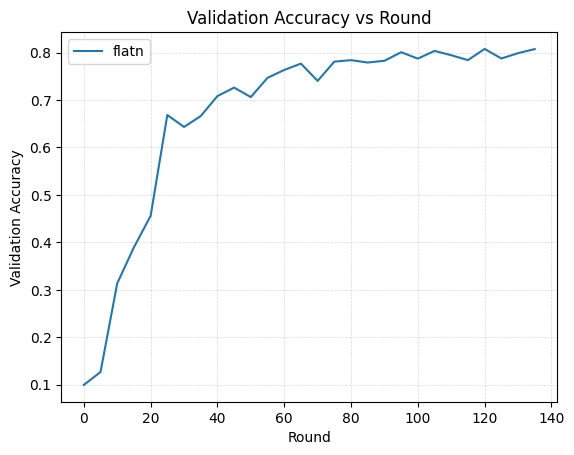

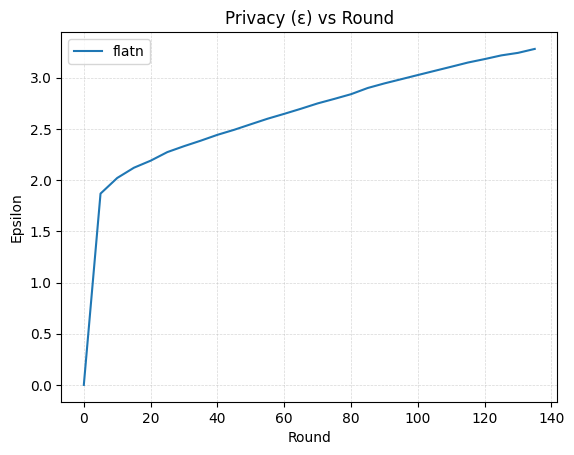

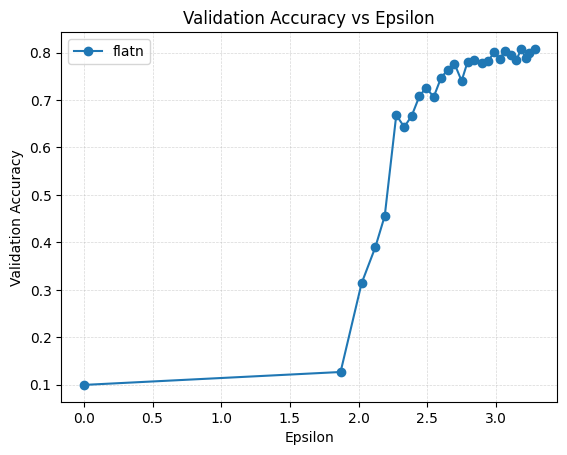

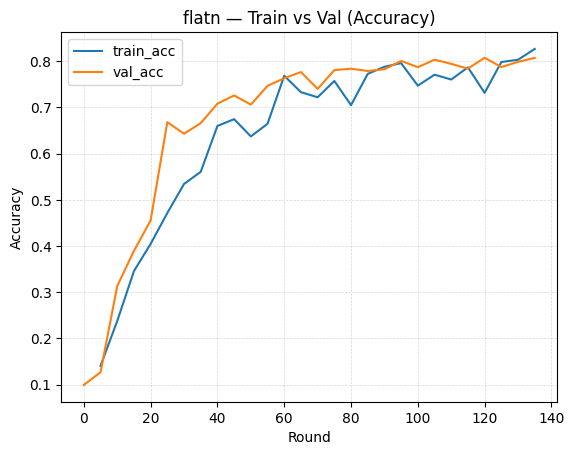

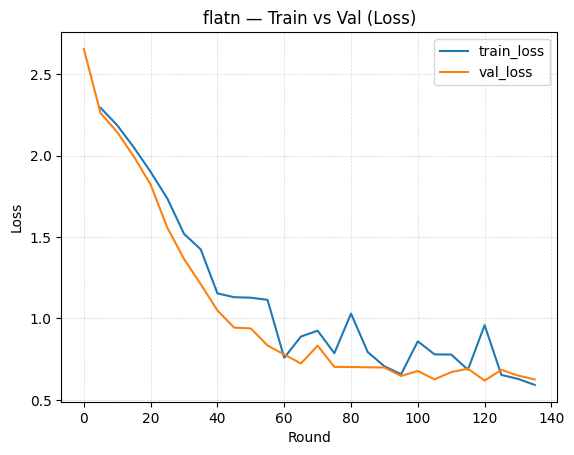

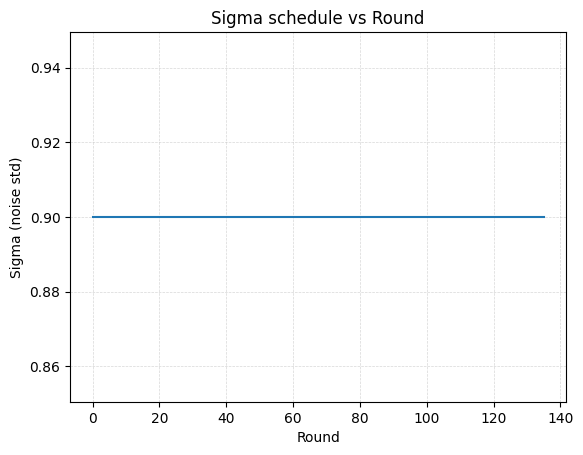

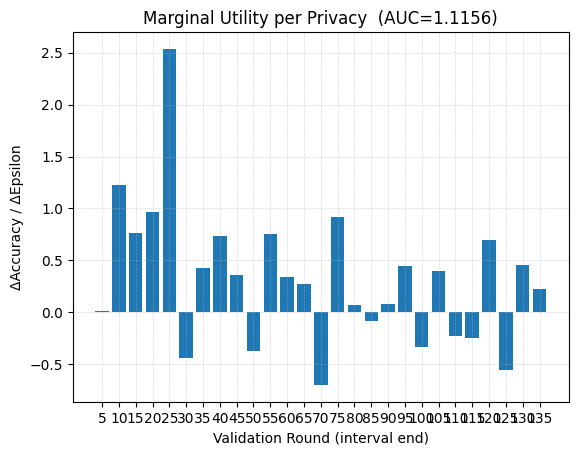

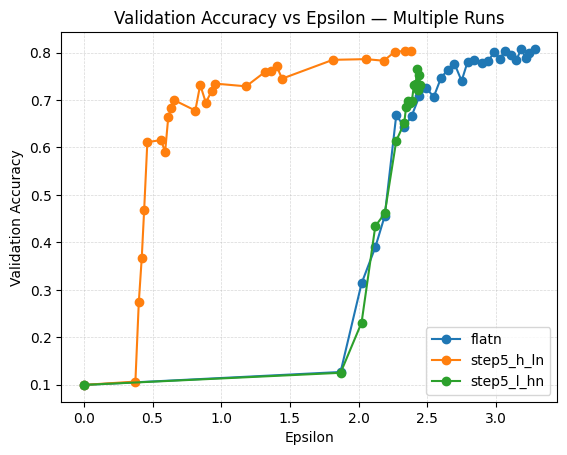

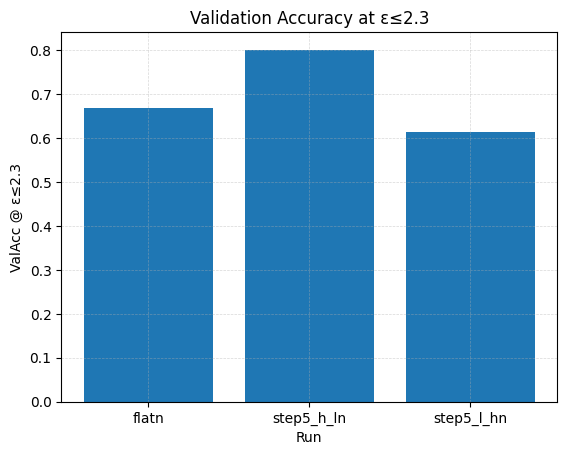

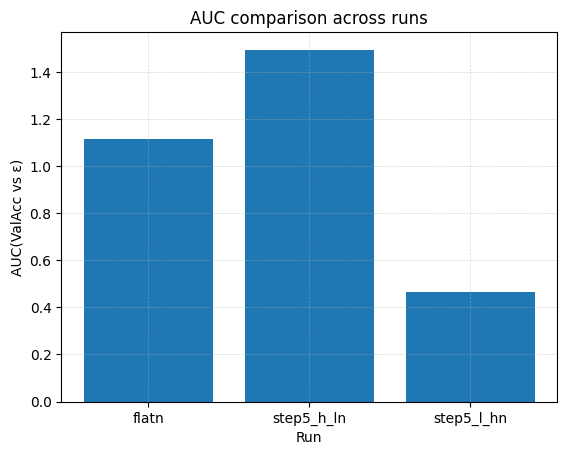

          run  last_round  last_eps  best_val  best_round  best_eps  \
0       flatn         135  3.281918  0.807698         120  3.182595   
1  step5_h_ln         130  2.379975  0.803869         125  2.338572   
2  step5_l_hn          80  2.448890  0.764766          65  2.424438   

   auc_valacc_eps  val_at_eps_1.5  val_at_eps_2.0  val_at_eps_2.3  \
0        1.115578        0.099483        0.126721        0.668381   
1        1.494191        0.745010        0.784698        0.801122   
2        0.465864        0.099483        0.125026        0.614081   

   val_at_eps_3.0  
0        0.800772  
1        0.802408  
2        0.731858  


In [ ]:
# 1) Point to your logs folder (you’re writing here already)
BASE_DIR = "/content/drive/MyDrive/tff_runs"

# 2) Load one or many runs
runs = load_runs_from_dir(BASE_DIR)  # picks up all *.csv
# or load specific files:
# runs = {
#   "step5_low_to_high": load_run_csv(f"{BASE_DIR}/step5_l_h.csv", "step5_low_to_high"),
#   "step5_high_to_low": load_run_csv(f"{BASE_DIR}/step5_h_l.csv", "step5_high_to_low"),
# }

# 3) Single-run visuals (replace 'some_run' with a key from runs)
df = runs[list(runs.keys())[0]]
plot_val_vs_round(df)
plot_eps_vs_round(df)
plot_val_vs_epsilon(df)
plot_train_vs_val_rounds(df)    # two separate charts, no subplots
plot_sigma_vs_round(df)
plot_mupe_bars(df)              # shows Δacc/Δε + AUC in title

# 4) Cross-run comparisons
plot_runs_val_vs_epsilon(runs)            # many lines on one chart
bar_compare_at_eps(runs, eps_cap=2.3)     # bars at a shared ε cap
bar_compare_auc(runs)                     # bars of AUC

# 5) Summary table you can export for thesis appendix
summary = summarize_runs(runs, eps_caps=(1.5, 2.0, 2.3, 3.0))
print(summary)
# summary.to_csv(f"{BASE_DIR}/_summary.csv", index=False)


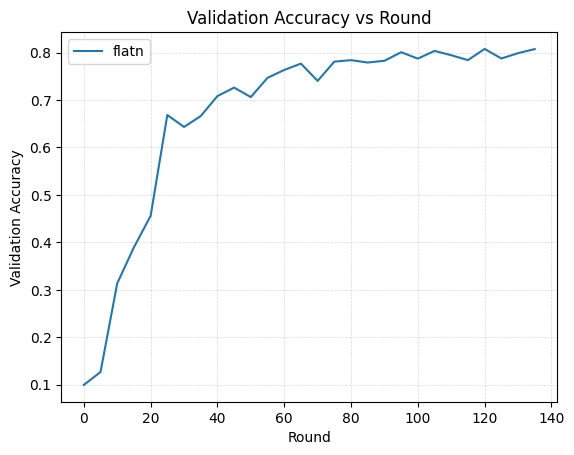

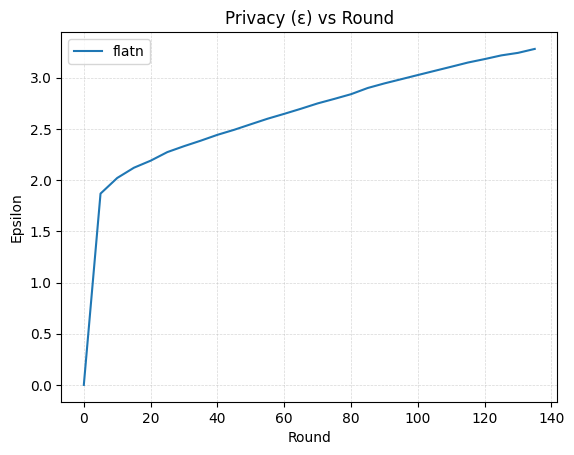

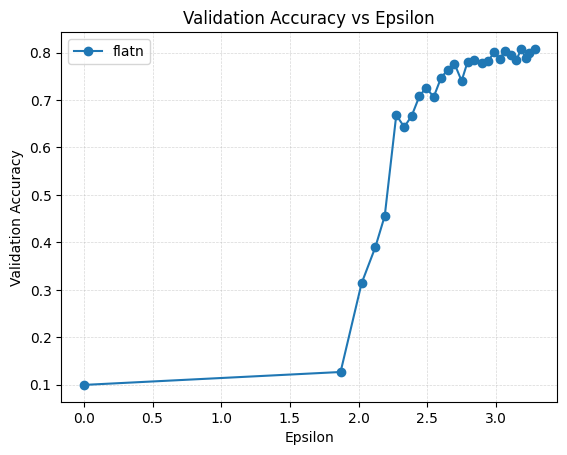

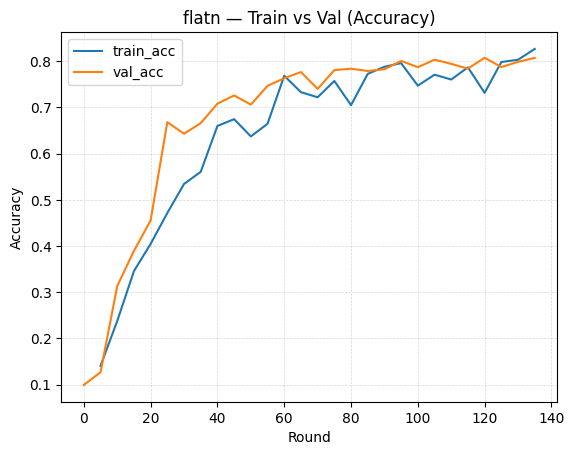

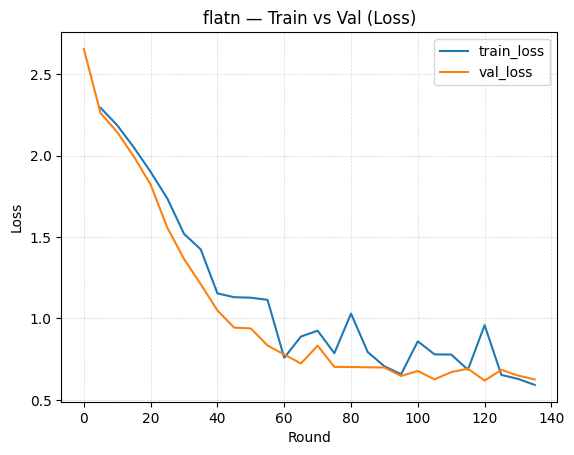

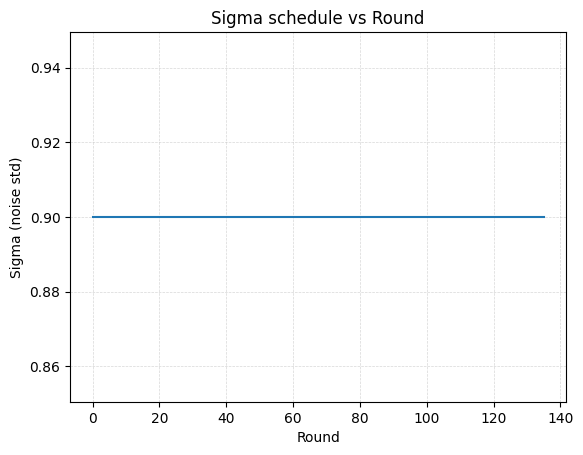

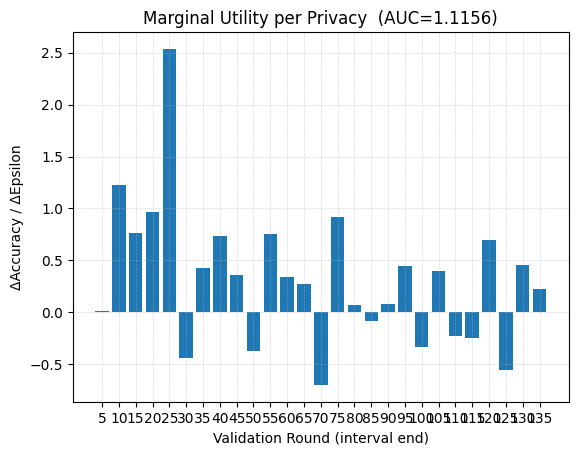

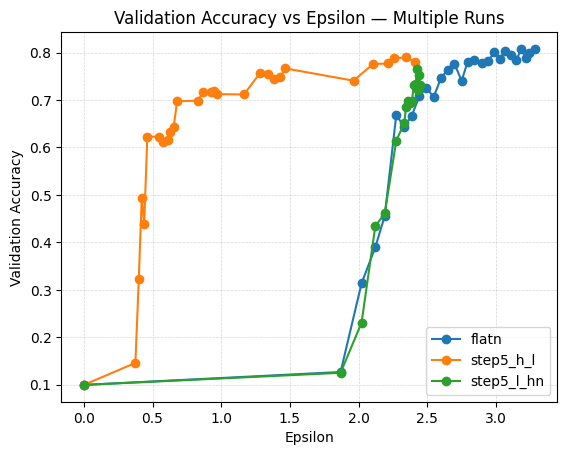

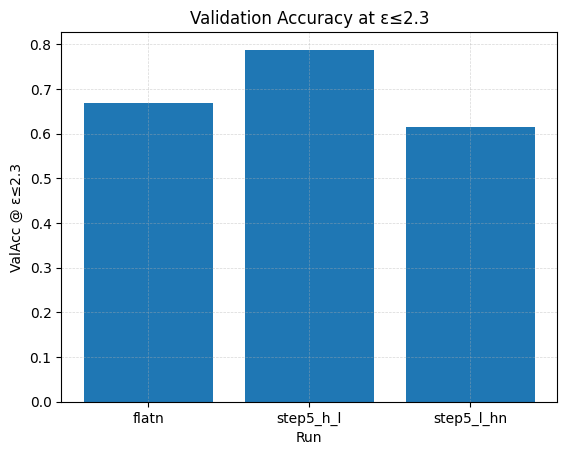

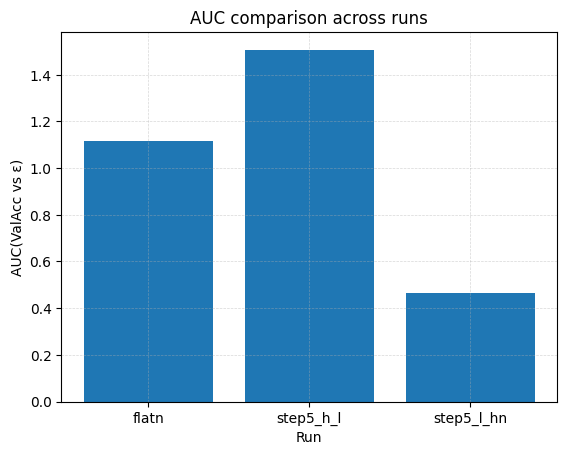

          run  last_round  last_eps  best_val  best_round  best_eps  \
0       flatn         135  3.281918  0.807698         120  3.182595   
1   step5_h_l         140  2.410852  0.789695         135  2.345430   
2  step5_l_hn          80  2.448890  0.764766          65  2.424438   

   auc_valacc_eps  val_at_eps_1.5  val_at_eps_2.0  val_at_eps_2.3  \
0        1.115578        0.099483        0.126721        0.668381   
1        1.507417        0.766636        0.740743        0.788059   
2        0.465864        0.099483        0.125026        0.614081   

   val_at_eps_3.0  
0        0.800772  
1        0.780431  
2        0.731858  


In [ ]:
# 1) Point to your logs folder (you’re writing here already)
BASE_DIR = "/content/"

# 2) Load one or many runs
runs = load_runs_from_dir(BASE_DIR)  # picks up all *.csv
# or load specific files:
# runs = {
#   "step5_low_to_high": load_run_csv(f"{BASE_DIR}/step5_l_h.csv", "step5_low_to_high"),
#   "step5_high_to_low": load_run_csv(f"{BASE_DIR}/step5_h_l.csv", "step5_high_to_low"),
# }

# 3) Single-run visuals (replace 'some_run' with a key from runs)
df = runs[list(runs.keys())[0]]
plot_val_vs_round(df)
plot_eps_vs_round(df)
plot_val_vs_epsilon(df)
plot_train_vs_val_rounds(df)    # two separate charts, no subplots
plot_sigma_vs_round(df)
plot_mupe_bars(df)              # shows Δacc/Δε + AUC in title

# 4) Cross-run comparisons
plot_runs_val_vs_epsilon(runs)            # many lines on one chart
bar_compare_at_eps(runs, eps_cap=2.3)     # bars at a shared ε cap
bar_compare_auc(runs)                     # bars of AUC

# 5) Summary table you can export for thesis appendix
summary = summarize_runs(runs, eps_caps=(1.5, 2.0, 2.3, 3.0))
print(summary)
# summary.to_csv(f"{BASE_DIR}/_summary.csv", index=False)


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- helpers ----------
def pick_three_runs(runs, names=None):
    """Return an OrderedDict with exactly 3 runs."""
    if names is None:
        names = list(runs.keys())[:3]
    out = {}
    for n in names:
        if n in runs:
            out[n] = runs[n]
        else:
            raise KeyError(f"Run '{n}' not found. Available: {list(runs.keys())[:8]}...")
    if len(out) != 3:
        raise ValueError(f"Need exactly 3 runs, got {len(out)}: {list(out.keys())}")
    return out

def _finalize(ax, title):
    ax.set_title(title)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.5)
    ax.legend()
    plt.show()

# ---------- multi-run 2D comparisons ----------
def plot_multi_val_acc_vs_round(runs3, title="Validation Accuracy vs Round (3 runs)"):
    fig, ax = plt.subplots()
    for name, df in runs3.items():
        d = df.dropna(subset=["round","val_acc"])
        if len(d): ax.plot(d["round"], d["val_acc"], label=name)
    ax.set_xlabel("Round"); ax.set_ylabel("Validation Accuracy")
    _finalize(ax, title)

def plot_multi_train_acc_vs_round(runs3, title="Train Accuracy vs Round (3 runs)"):
    fig, ax = plt.subplots()
    for name, df in runs3.items():
        d = df.dropna(subset=["round","train_acc"])
        if len(d): ax.plot(d["round"], d["train_acc"], label=name)
    ax.set_xlabel("Round"); ax.set_ylabel("Train Accuracy")
    _finalize(ax, title)

def plot_multi_val_loss_vs_round(runs3, title="Validation Loss vs Round (3 runs)"):
    fig, ax = plt.subplots()
    for name, df in runs3.items():
        d = df.dropna(subset=["round","val_loss"])
        if len(d): ax.plot(d["round"], d["val_loss"], label=name)
    ax.set_xlabel("Round"); ax.set_ylabel("Validation Loss")
    _finalize(ax, title)

def plot_multi_train_loss_vs_round(runs3, title="Train Loss vs Round (3 runs)"):
    fig, ax = plt.subplots()
    for name, df in runs3.items():
        d = df.dropna(subset=["round","train_loss"])
        if len(d): ax.plot(d["round"], d["train_loss"], label=name)
    ax.set_xlabel("Round"); ax.set_ylabel("Train Loss")
    _finalize(ax, title)

def plot_multi_eps_vs_round(runs3, title="Epsilon vs Round (3 runs)"):
    fig, ax = plt.subplots()
    for name, df in runs3.items():
        d = df.dropna(subset=["round","epsilon"])
        if len(d): ax.plot(d["round"], d["epsilon"], label=name)
    ax.set_xlabel("Round"); ax.set_ylabel("Epsilon")
    _finalize(ax, title)

def plot_multi_val_acc_vs_epsilon(runs3, title="Validation Accuracy vs Epsilon (3 runs)"):
    fig, ax = plt.subplots()
    for name, df in runs3.items():
        d = df.dropna(subset=["epsilon","val_acc"]).sort_values("epsilon")
        if len(d): ax.plot(d["epsilon"], d["val_acc"], marker="o", linestyle="-", label=name)
    ax.set_xlabel("Epsilon"); ax.set_ylabel("Validation Accuracy")
    _finalize(ax, title)

# ---------- 3D curve: (round, epsilon, accuracy) ----------
def plot_3d_round_eps_acc(runs3, metric="val_acc",
                          title="(Round, Epsilon, Accuracy) — 3D"):
    from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    for name, df in runs3.items():
        d = df.dropna(subset=["round","epsilon",metric]).sort_values("round")
        if len(d):
            ax.plot(d["round"].values, d["epsilon"].values, d[metric].values, label=name)
    ax.set_xlabel("Round"); ax.set_ylabel("Epsilon"); ax.set_zlabel(metric)
    ax.set_title(title)
    ax.legend()
    plt.show()

# ---------- compact comparison table at one ε-cap ----------
def compare_three_at_eps(runs3, eps_cap=2.3):
    from math import isnan
    rows = []
    for name, df in runs3.items():
        dv = df.dropna(subset=["epsilon","val_acc","round"]).sort_values("epsilon")
        if len(dv)==0:
            rows.append({"run":name, "round_at_cap":None, "val_acc_at_cap":None, "train_acc_at_cap":None})
            continue
        # interpolate validation acc at cap
        eps = dv["epsilon"].values; acc = dv["val_acc"].values; rnd = dv["round"].values
        if eps[-1] <= eps_cap:
            r_cap, a_cap = int(rnd[-1]), float(acc[-1])
        elif eps_cap <= eps[0]:
            r_cap, a_cap = int(rnd[0]), float(acc[0])
        else:
            i = np.searchsorted(eps, eps_cap, side="right")
            e0,e1 = eps[i-1], eps[i]; a0,a1 = acc[i-1], acc[i]; r0,r1 = rnd[i-1], rnd[i]
            t = (eps_cap - e0) / (e1 - e0 + 1e-12)
            r_cap = int(round(r0 + t*(r1-r0)))
            a_cap = float(a0 + t*(a1-a0))
        # nearest train acc at that round (not interpolated)
        da = df.sort_values("round")
        ta = da.loc[(da["round"]-r_cap).abs().idxmin(), "train_acc"] if "train_acc" in da else np.nan
        rows.append({"run":name, "round_at_cap":r_cap, "val_acc_at_cap":a_cap, "train_acc_near_cap":(None if pd.isna(ta) else float(ta))})
    return pd.DataFrame(rows)


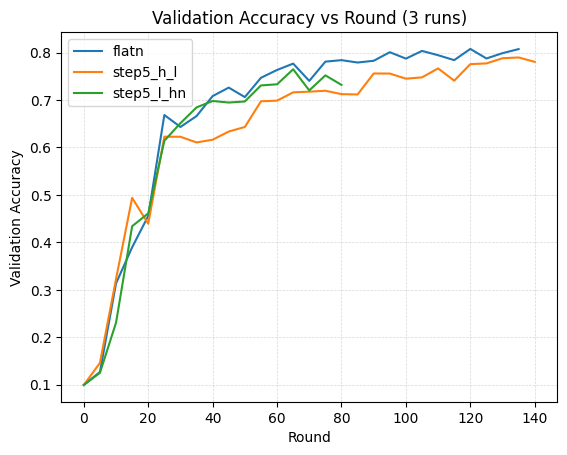

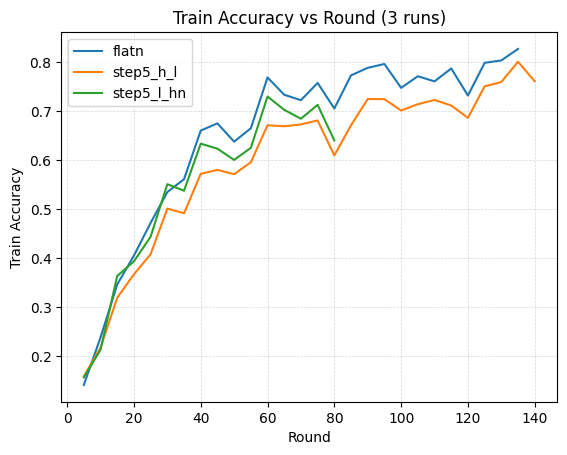

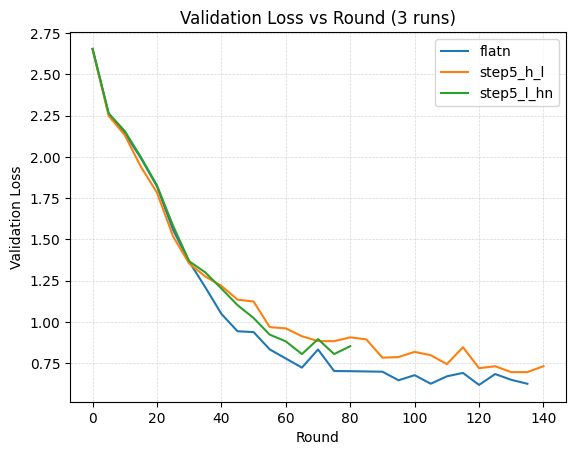

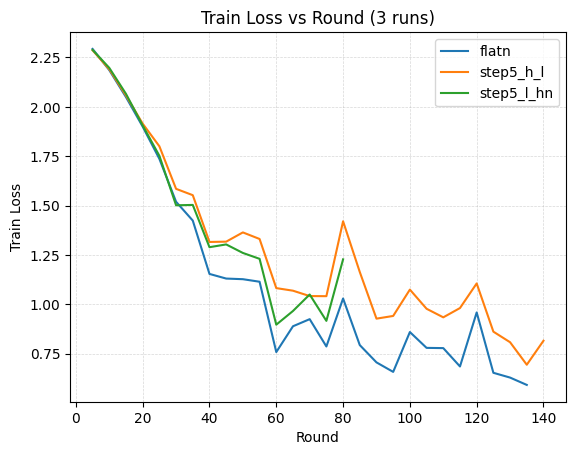

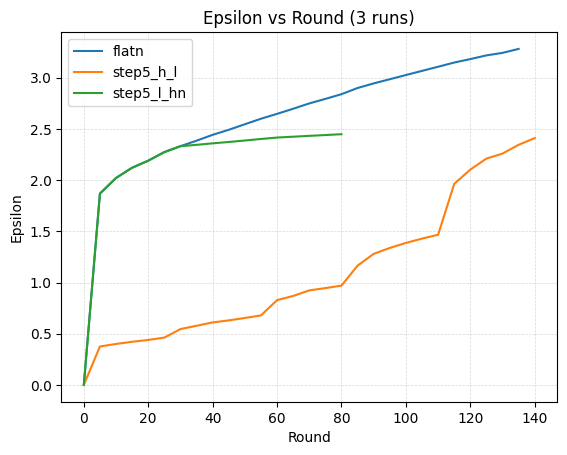

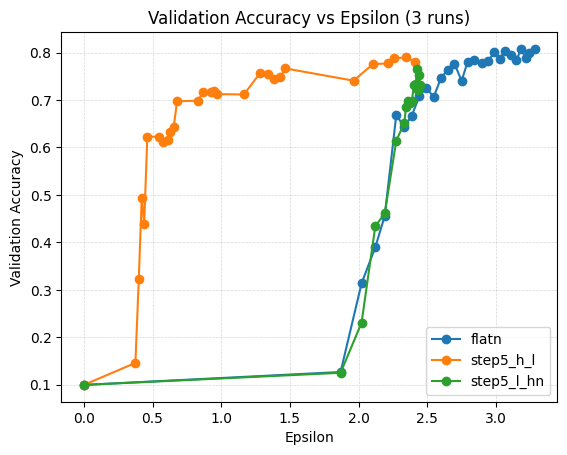

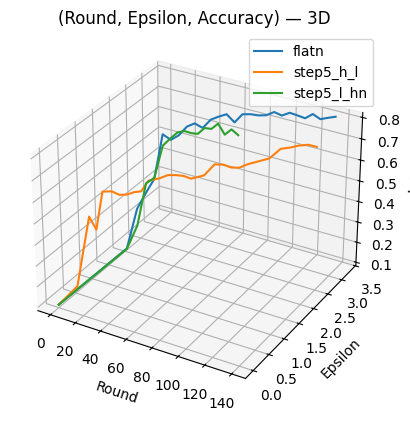

          run  round_at_cap  val_acc_at_cap  train_acc_near_cap
0       flatn            27        0.657094            0.471643
1   step5_h_l           132        0.788828            0.759214
2  step5_l_hn            27        0.630724            0.443394


In [ ]:
BASE_DIR = "/content"  # or your folder
runs = load_runs_from_dir(BASE_DIR)

# pick exactly three runs you want to compare
# names = ["step5_l_h", "step5_h_l", "flat_sigma"]  # example
names = list(runs.keys())[:3]
runs3 = pick_three_runs(runs, names)

# lines comparisons
plot_multi_val_acc_vs_round(runs3)
plot_multi_train_acc_vs_round(runs3)
plot_multi_val_loss_vs_round(runs3)
plot_multi_train_loss_vs_round(runs3)
plot_multi_eps_vs_round(runs3)
plot_multi_val_acc_vs_epsilon(runs3)

# 3D curve (use metric="train_acc" if you want train accuracy instead)
plot_3d_round_eps_acc(runs3, metric="val_acc")

# table at a shared ε-cap (add to thesis appendix)
cmp23 = compare_three_at_eps(runs3, eps_cap=2.3)
print(cmp23)
# cmp23.to_csv(f"{BASE_DIR}/compare_three_eps23.csv", index=False)



=== Comparison table ===
                  run  test_acc  test_loss  rounds    eps  acc_per_eps  \
0  flat_adaptive_clip    0.8126     0.5950     135  3.282       0.2476   
1   step5_low_to_high    0.7721     0.7806      80  2.441       0.3163   
2   step5_high_to_low    0.7850     0.7040     140  2.411       0.3256   

   eps_per_acc  %_acc_vs_flat  %_eps_vs_flat  %_acc_per_eps_vs_flat  
0       4.0389         0.0000         0.0000                 0.0000  
1       3.1615        -4.9840       -25.6246                27.7519  
2       3.0713        -3.3965       -26.5387                31.5026  


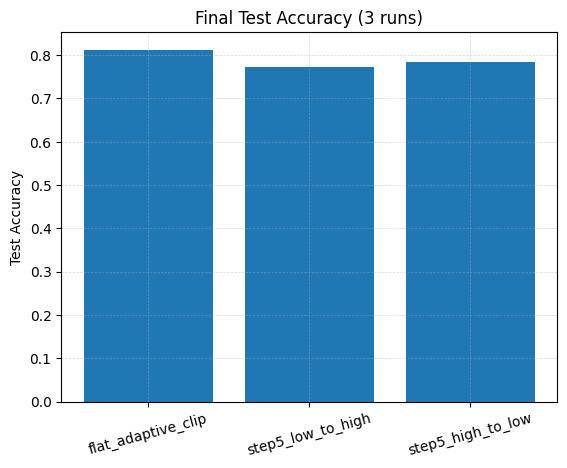

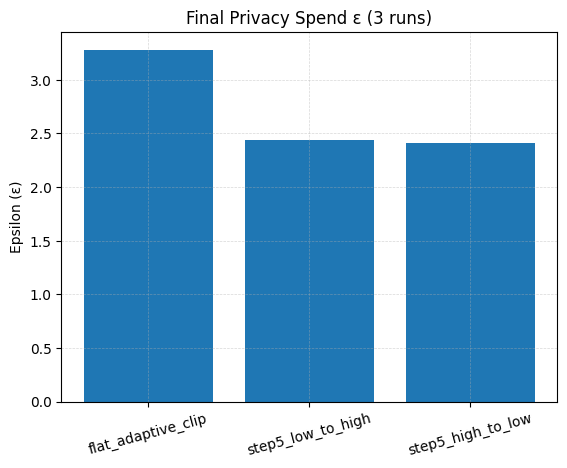

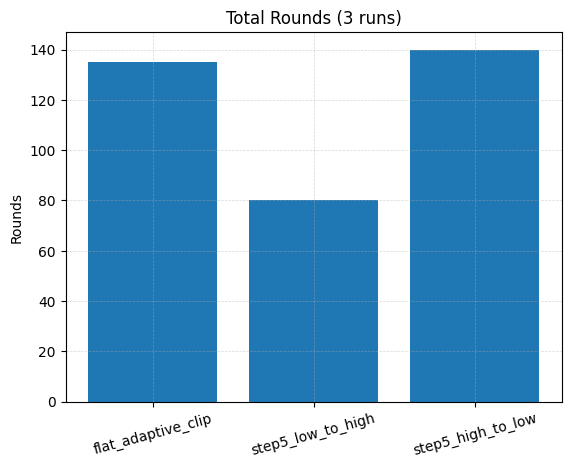

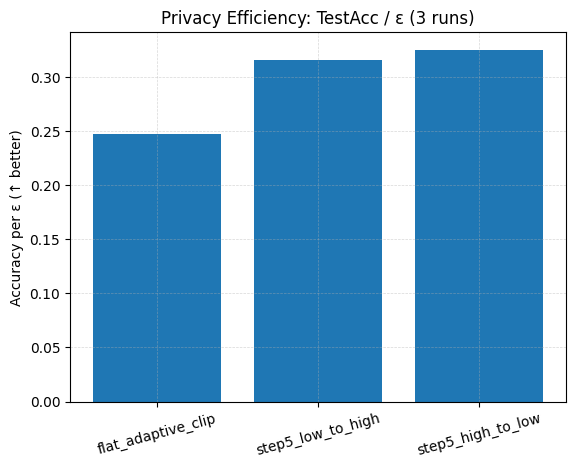

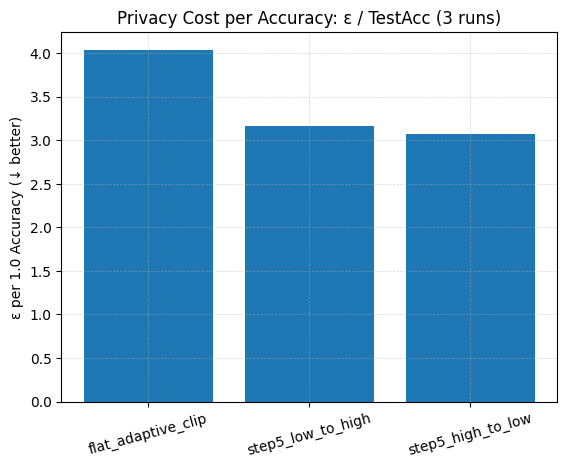

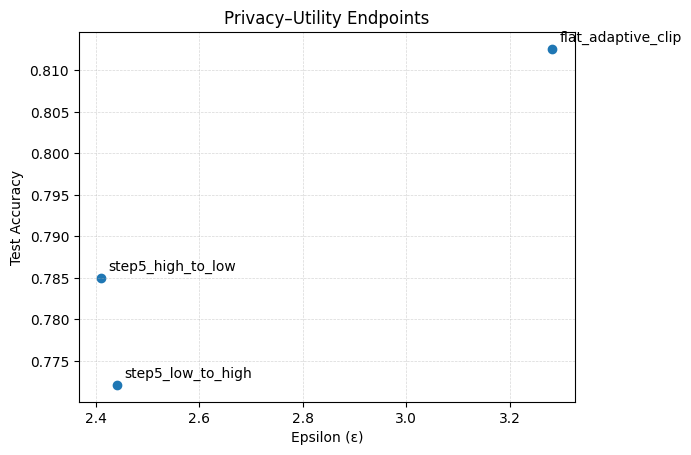

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----- your three endpoints -----
data = [
    {"run": "flat_adaptive_clip", "test_acc": 0.8126, "test_loss": 0.5950, "rounds": 135, "eps": 3.282},
    {"run": "step5_low_to_high",  "test_acc": 0.7721, "test_loss": 0.7806, "rounds": 80, "eps": 2.441},
    {"run": "step5_high_to_low",  "test_acc": 0.7850, "test_loss": 0.7040, "rounds": 140, "eps": 2.411},
]
df = pd.DataFrame(data)

# ----- derived metrics -----
df["acc_per_eps"] = df["test_acc"] / df["eps"]          # privacy-efficiency (higher is better)
df["eps_per_acc"] = df["eps"] / df["test_acc"]          # ε needed per 1.0 accuracy (lower is better)

# % deltas vs flat baseline
base = df.loc[df["run"]=="flat_adaptive_clip"].iloc[0]
df["%_acc_vs_flat"]        = 100.0 * (df["test_acc"]/base["test_acc"] - 1.0)
df["%_eps_vs_flat"]        = 100.0 * (df["eps"]/base["eps"] - 1.0)
df["%_acc_per_eps_vs_flat"]= 100.0 * (df["acc_per_eps"]/(base["test_acc"]/base["eps"]) - 1.0)

print("\n=== Comparison table ===")
print(df.round(4))

# ----- plotting helpers -----
def _bar(metric, ylabel, title):
    fig, ax = plt.subplots()
    ax.bar(df["run"], df[metric])
    ax.set_ylabel(ylabel); ax.set_title(title); ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.5)
    plt.xticks(rotation=15); plt.show()

def _scatter_eps_acc():
    fig, ax = plt.subplots()
    ax.scatter(df["eps"], df["test_acc"])
    for _, r in df.iterrows():
        ax.annotate(r["run"], (r["eps"], r["test_acc"]), xytext=(5,5), textcoords="offset points")
    ax.set_xlabel("Epsilon (ε)"); ax.set_ylabel("Test Accuracy"); ax.set_title("Privacy–Utility Endpoints")
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.5); plt.show()

# ----- figures to drop in the thesis -----
_bar("test_acc",    "Test Accuracy",                  "Final Test Accuracy (3 runs)")
_bar("eps",         "Epsilon (ε)",                    "Final Privacy Spend ε (3 runs)")
_bar("rounds",      "Rounds",                         "Total Rounds (3 runs)")
_bar("acc_per_eps", "Accuracy per ε (↑ better)",      "Privacy Efficiency: TestAcc / ε (3 runs)")
_bar("eps_per_acc", "ε per 1.0 Accuracy (↓ better)",  "Privacy Cost per Accuracy: ε / TestAcc (3 runs)")
_scatter_eps_acc()

# Optional: save a summary CSV you can reuse later
df.to_csv("/content/final_endpoints_summary.csv", index=False)
